Shape: (2000, 18)


,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,membership,orders_last_12m,annual_spend
0,QB100000,2023-11-27,Lucknow,2,Female,Android,Referral,21.0,35.6,13,45.3,572.0,NaN,21.6,4.0,Basic,17,8675.0
1,QB100001,2025-05-26,Bengaluru,1,Female,iOS,Influencer,43.0,17.4,11,21.9,329.0,4.9,0.0,13.0,Basic,24,7896.0
2,QB100002,2023-02-06,Indore,3,Male,iOS,Referral,39.0,45.4,12,47.9,118.0,3.8,17.8,1.0,Basic,17,1826.0
3,QB100003,2024-04-09,Jaipur,2,Female,Android,Paid Social,34.0,31.2,13,26.4,303.0,NaN,42.9,7.0,Basic,379,90202.0
4,QB100004,2025-04-12,Mumbai,1,Male,Android,Search Ads,33.0,18.9,17,19.4,191.0,4.0,29.2,12.0,Basic,17,2773.0


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
customer_id,2000,2000,QB100000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
signup_date,2000,NaN,NaN,NaN,2024-05-28 18:57:36,2023-01-01 00:00:00,2023-09-18 18:00:00,2024-05-29 12:00:00,2025-02-15 06:00:00,2025-11-05 00:00:00,NaN
city,2000,10,Mumbai,320,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city_tier,2000.0,NaN,NaN,NaN,1.6005,1.0,1.0,1.0,2.0,3.0,0.772138
gender,1894,3,Male,1023,NaN,NaN,NaN,NaN,NaN,NaN,NaN
device_type,2000,3,Android,1171,NaN,NaN,NaN,NaN,NaN,NaN,NaN
acquisition_channel,2000,5,Organic,592,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,1861.0,NaN,NaN,NaN,31.926384,0.0,27.0,32.0,37.0,150.0,7.619334
tenure_months,2000.0,NaN,NaN,NaN,29.5073,12.0,20.775,29.5,37.925,46.6,9.981302
app_sessions_per_month,2000.0,NaN,NaN,NaN,13.932,2.0,11.0,14.0,16.0,29.0,3.77856


,missing_count,missing_pct
customer_rating,258,12.90
age,139,6.95
avg_order_value,108,5.40
gender,106,5.30
discount_used_pct,104,5.20
delivery_time_min,80,4.00


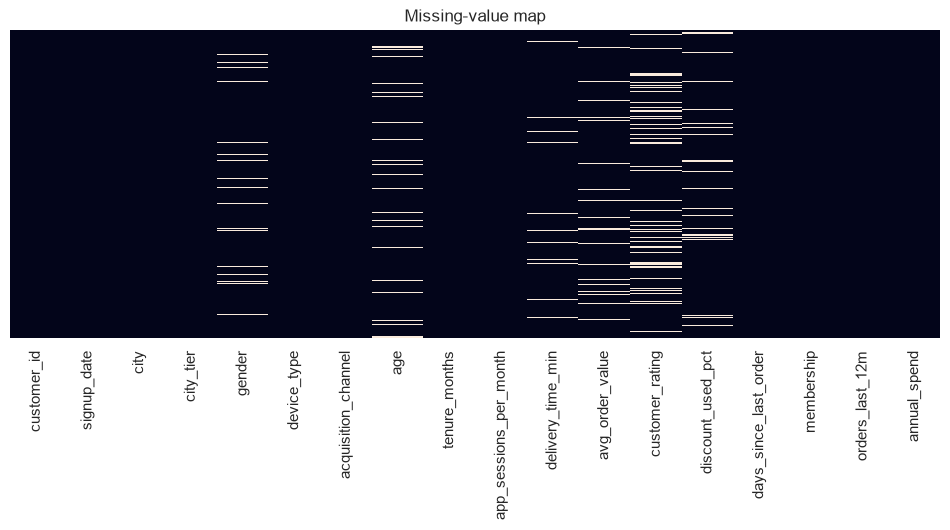

In [22]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
sns.set_theme(style='whitegrid')
df_raw = pd.read_csv('quickbite_customers.csv')
df = df_raw.copy()
df['signup_date'] = pd.to_datetime(df['signup_date'], errors='coerce')
print('Shape:', df.shape)
display(df.head())
display(df.describe(include='all').T)
missing = pd.DataFrame({'missing_count':df.isna().sum(),'missing_pct':df.isna().mean()*100})
display(missing[missing.missing_count > 0].sort_values('missing_count',ascending=False))
plt.figure(figsize=(12,4)); sns.heatmap(df_raw.isna(),cbar=False,yticklabels=False); plt.title('Missing-value map'); plt.show()

## Task 1–2: Missing values and outliers
Cleaning policy: age below 18 or above 100 is treated as impossible and set to missing; average order value above ₹5,000 is treated as an implausible entry and set to missing; delivery time above 120 minutes is retained as a service incident but capped at 120 for robust descriptive analysis. Missing numeric values are median-imputed; AOV uses city-tier median. Missing gender is labelled Unknown. These cutoffs are analytical assumptions to validate with source-system owners.

IQR and Z-score are diagnostics, not automatic deletion rules. High annual spend and high order counts are retained because they may represent genuine VIP customers.

In [24]:
for col in ['age','delivery_time_min','avg_order_value']:
    s=df_raw[col].dropna(); q1,q3=s.quantile([.25,.75]); iqr=q3-q1
    iqr_n=((s<q1-1.5*iqr)|(s>q3+1.5*iqr)).sum()
    z_n=(np.abs((s-s.mean())/s.std(ddof=0))>3).sum()
    print(col, 'IQR flags=',int(iqr_n),'Z-score flags=',int(z_n))
df['age']=df['age'].mask((df.age<18)|(df.age>100))
df['delivery_extreme_flag']=df.delivery_time_min>120
df['delivery_time_min']=df.delivery_time_min.clip(upper=120)
df['avg_order_value']=df.avg_order_value.mask(df.avg_order_value>5000)
df['age']=df.age.fillna(df.age.median())
df['delivery_time_min']=df.delivery_time_min.fillna(df.delivery_time_min.median())
df['avg_order_value']=df.avg_order_value.fillna(df.groupby('city_tier').avg_order_value.transform('median'))
df['customer_rating']=df.customer_rating.fillna(df.customer_rating.median())
df['discount_used_pct']=df.discount_used_pct.fillna(df.discount_used_pct.median())
df['gender']=df.gender.fillna('Unknown')
print('Remaining missing cells:',int(df.isna().sum().sum()))
display(df.head())

age IQR flags= 9 Z-score flags= 5
delivery_time_min IQR flags= 46 Z-score flags= 4
avg_order_value IQR flags= 96 Z-score flags= 4
Remaining missing cells: 0


,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,membership,orders_last_12m,annual_spend,delivery_extreme_flag
0,QB100000,2023-11-27,Lucknow,2,Female,Android,Referral,21.0,35.6,13,45.3,572.0,4.4,21.6,4.0,Basic,17,8675.0,False
1,QB100001,2025-05-26,Bengaluru,1,Female,iOS,Influencer,43.0,17.4,11,21.9,329.0,4.9,0.0,13.0,Basic,24,7896.0,False
2,QB100002,2023-02-06,Indore,3,Male,iOS,Referral,39.0,45.4,12,47.9,118.0,3.8,17.8,1.0,Basic,17,1826.0,False
3,QB100003,2024-04-09,Jaipur,2,Female,Android,Paid Social,34.0,31.2,13,26.4,303.0,4.4,42.9,7.0,Basic,379,90202.0,False
4,QB100004,2025-04-12,Mumbai,1,Male,Android,Search Ads,33.0,18.9,17,19.4,191.0,4.0,29.2,12.0,Basic,17,2773.0,False


## Task 3: Distribution shapes
Inspect histograms/KDE and skewness. Use log(AOV) to examine whether a log transform makes its distribution more symmetric. Mean, median and mode help explain skew: for right-skewed data, the mean is commonly pulled above the median; for left-skewed data it is commonly pulled below.

age skew= 0.13 mean= 31.9 median= 32.0 mode= 32.0


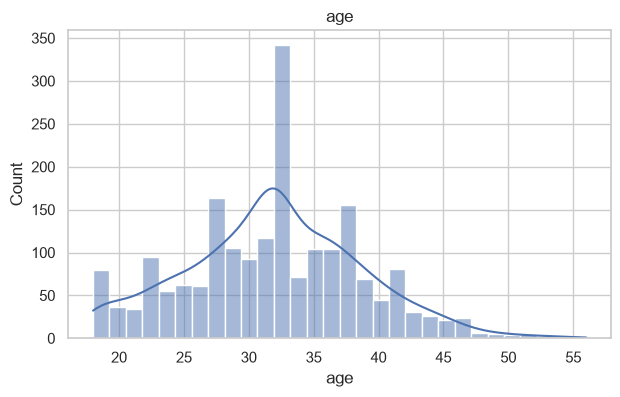

customer_rating skew= -1.81 mean= 4.3 median= 4.4 mode= 4.4


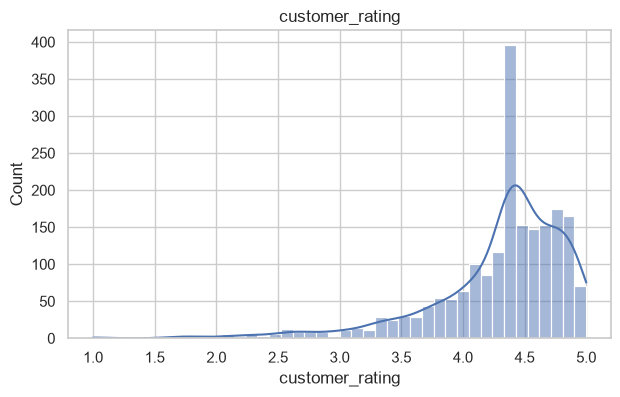

delivery_time_min skew= 1.64 mean= 34.37 median= 32.25 mode= 32.25


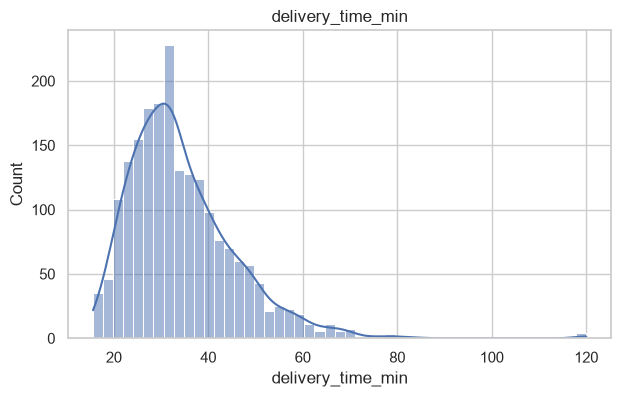

avg_order_value skew= 1.83 mean= 364.61 median= 316.0 mode= 325.0


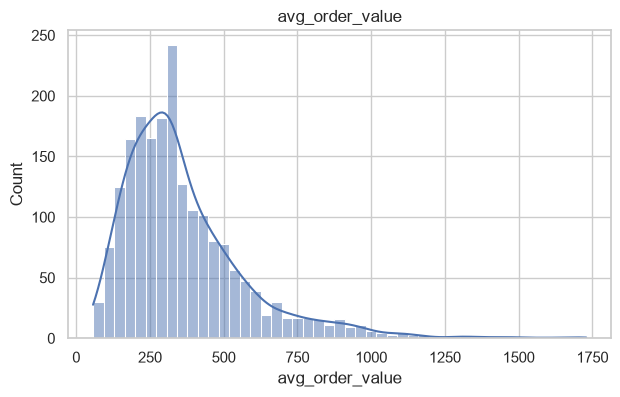

annual_spend skew= 15.24 mean= 12995.85 median= 7142.0 mode= 2916.0


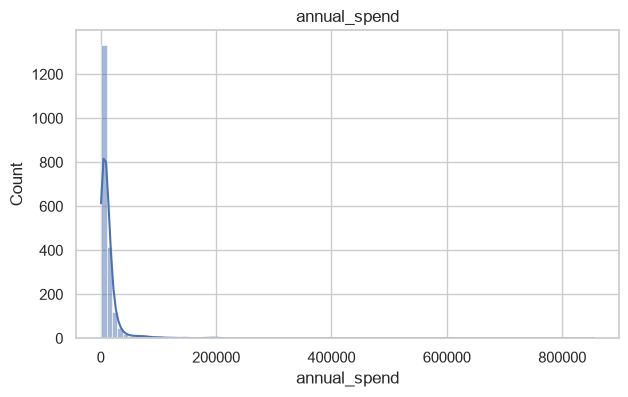

orders_last_12m skew= 5.31 mean= 34.9 median= 24.0 mode= 17


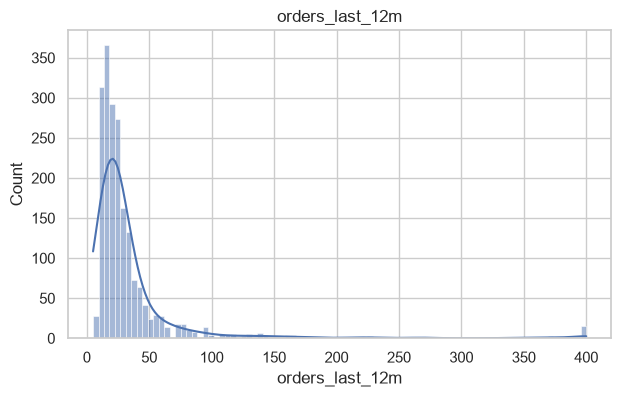

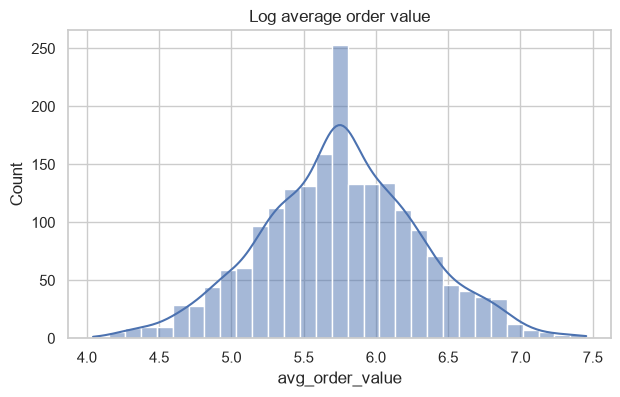

In [26]:
for col in ['age','customer_rating','delivery_time_min','avg_order_value','annual_spend','orders_last_12m']:
    print(col, 'skew=',round(df[col].skew(),2),'mean=',round(df[col].mean(),2),'median=',round(df[col].median(),2),'mode=',round(df[col].mode().iloc[0],2))
    plt.figure(figsize=(7,4)); sns.histplot(df[col],kde=True); plt.title(col); plt.show()
plt.figure(figsize=(7,4)); sns.histplot(np.log(df.avg_order_value),kde=True); plt.title('Log average order value'); plt.show()

## Task 4: Relationships
Correlation is unitless and ranges from -1 to +1, so it is easier to compare across variables. Covariance depends on measurement units. Correlation does not prove causation.

,city_tier,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,orders_last_12m,annual_spend
city_tier,0.596198,0.071885,0.117375,0.052360,1.757439,-2.005203e+01,-0.001903,-0.155975,0.377689,9.481258e-01,-1.021972e+02
age,0.071885,46.170481,1.053792,-0.412370,4.953994,1.775361e+01,-0.018818,-15.990960,-1.855177,2.916815e+00,5.424296e+03
tenure_months,0.117375,1.053792,99.626390,-0.193750,-0.476482,-2.797849e+01,0.108426,-0.158046,-2.991722,-7.673531e+00,-3.633604e+03
app_sessions_per_month,0.052360,-0.412370,-0.193750,14.277515,-1.606883,3.060976e+00,0.021467,-0.929122,1.871202,1.399696e+01,9.728321e+03
delivery_time_min,1.757439,4.953994,-0.476482,-1.606883,130.909152,-1.011872e+02,0.042233,-1.045665,-2.504823,-6.529143e+00,-3.625107e+03
avg_order_value,-20.052031,17.753608,-27.978489,3.060976,-101.187230,4.573956e+04,0.893479,-2.428539,-145.791291,2.151166e+02,1.636312e+06
customer_rating,-0.001903,-0.018818,0.108426,0.021467,0.042233,8.934790e-01,0.324972,-0.015444,-0.721559,-1.854270e-01,1.489031e+01
discount_used_pct,-0.155975,-15.990960,-0.158046,-0.929122,-1.045665,-2.428539e+00,-0.015444,85.265970,-6.063885,5.879196e+00,-8.300506e+03
days_since_last_order,0.377689,-1.855177,-2.991722,1.871202,-2.504823,-1.457913e+02,-0.721559,-6.063885,360.377288,8.827962e+00,-9.480868e+03
orders_last_12m,0.948126,2.916815,-7.673531,13.996960,-6.529143,2.151166e+02,-0.185427,5.879196,8.827962,2.427951e+03,1.083302e+06


,city_tier,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,orders_last_12m,annual_spend
city_tier,1.000000,0.013701,0.015230,0.017946,0.198930,-0.121428,-0.004324,-0.021876,0.025767,0.024920,-0.004363
age,0.013701,1.000000,0.015538,-0.016061,0.063722,0.012217,-0.004858,-0.254862,-0.014382,0.008712,0.026315
tenure_months,0.015230,0.015538,1.000000,-0.005137,-0.004172,-0.013107,0.019056,-0.001715,-0.015789,-0.015602,-0.012000
app_sessions_per_month,0.017946,-0.016061,-0.005137,1.000000,-0.037168,0.003788,0.009966,-0.026629,0.026086,0.075177,0.084869
delivery_time_min,0.198930,0.063722,-0.004172,-0.037168,1.000000,-0.041352,0.006475,-0.009897,-0.011532,-0.011581,-0.010444
avg_order_value,-0.121428,0.012217,-0.013107,0.003788,-0.041352,1.000000,0.007329,-0.001230,-0.035909,0.020413,0.252207
customer_rating,-0.004324,-0.004858,0.019056,0.009966,0.006475,0.007329,1.000000,-0.002934,-0.066676,-0.006601,0.000861
discount_used_pct,-0.021876,-0.254862,-0.001715,-0.026629,-0.009897,-0.001230,-0.002934,1.000000,-0.034593,0.012921,-0.029631
days_since_last_order,0.025767,-0.014382,-0.015789,0.026086,-0.011532,-0.035909,-0.066676,-0.034593,1.000000,0.009438,-0.016463
orders_last_12m,0.024920,0.008712,-0.015602,0.075177,-0.011581,0.020413,-0.006601,0.012921,0.009438,1.000000,0.724713


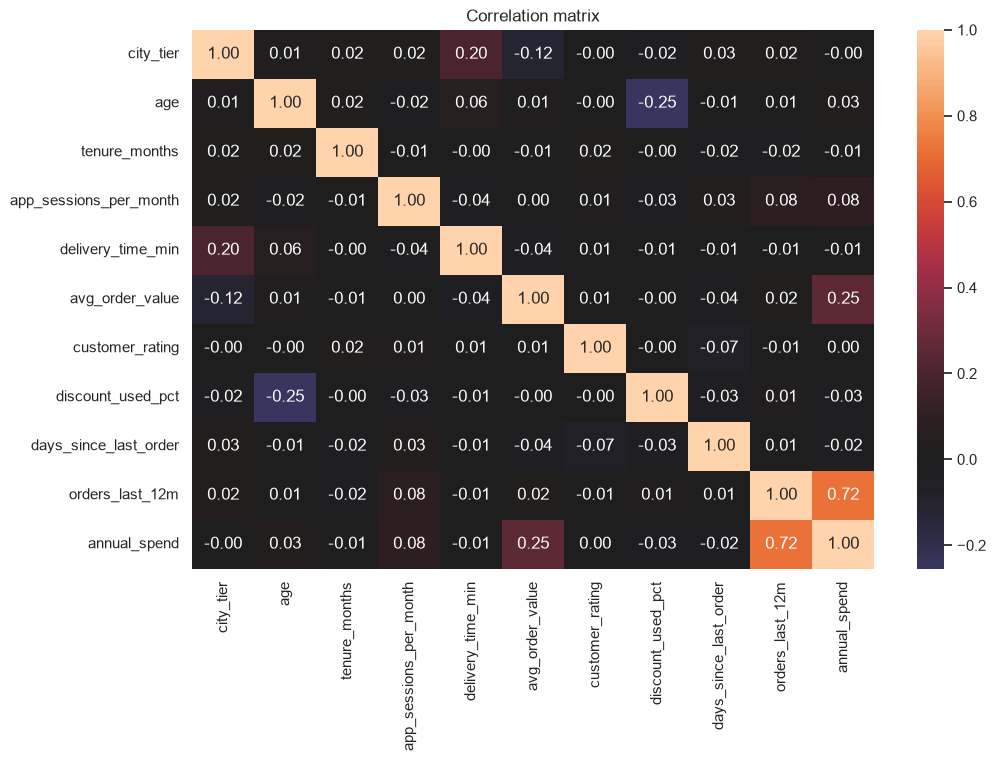

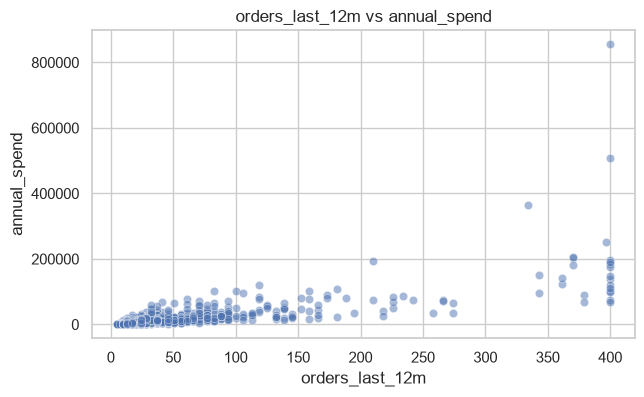

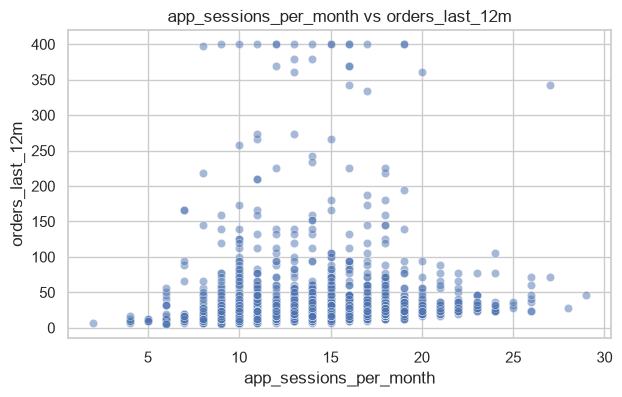

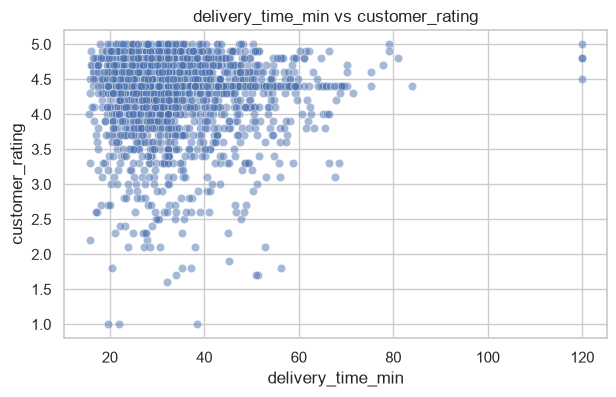

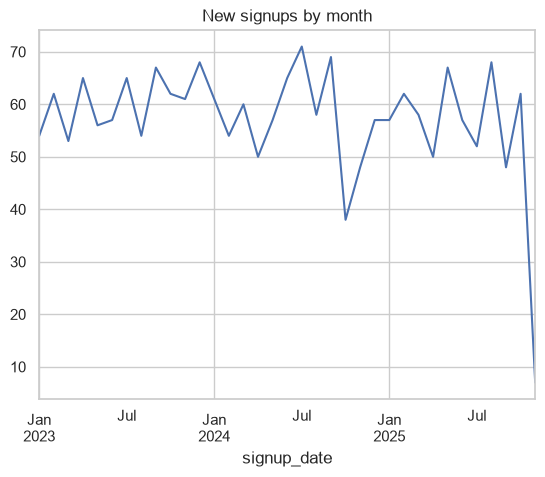

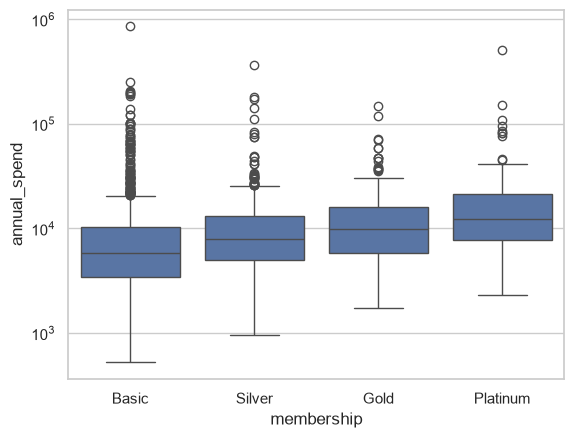

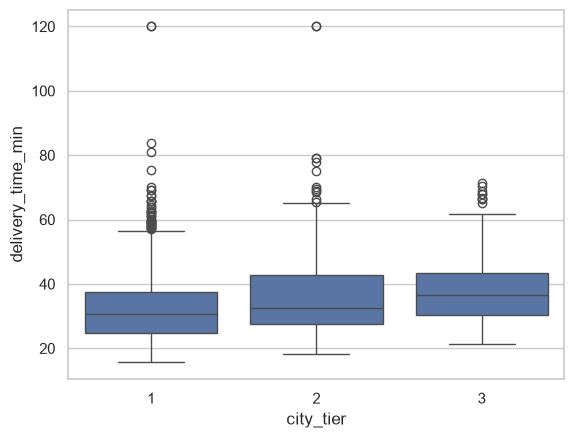

annual_spend              1.000000
orders_last_12m           0.724713
avg_order_value           0.252207
app_sessions_per_month    0.084869
age                       0.026315
customer_rating           0.000861
city_tier                -0.004363
delivery_time_min        -0.010444
tenure_months            -0.012000
days_since_last_order    -0.016463
discount_used_pct        -0.029631
Name: annual_spend, dtype: float64


In [28]:
numeric=df.select_dtypes(include='number')
display(numeric.cov()); display(numeric.corr())
plt.figure(figsize=(11,7)); sns.heatmap(numeric.corr(),annot=True,fmt='.2f',center=0); plt.title('Correlation matrix'); plt.show()
for x,y in [('orders_last_12m','annual_spend'),('app_sessions_per_month','orders_last_12m'),('delivery_time_min','customer_rating')]:
    plt.figure(figsize=(7,4)); sns.scatterplot(data=df,x=x,y=y,alpha=.5); plt.title(f'{x} vs {y}'); plt.show()
df.set_index('signup_date').resample('MS').size().plot(title='New signups by month'); plt.show()
sns.boxplot(data=df,x='membership',y='annual_spend',order=['Basic','Silver','Gold','Platinum']); plt.yscale('log'); plt.show()
sns.boxplot(data=df,x='city_tier',y='delivery_time_min'); plt.show()
print(numeric.corr()['annual_spend'].sort_values(ascending=False))

## Task 5: Categorical encoding
Membership is ordinal (Basic=0, Silver=1, Gold=2, Platinum=3). Device and acquisition channel are nominal and are one-hot encoded. City is nominal, so alphabetic integer encoding would falsely imply order. Target encoding uses city mean spend, but risks target leakage in predictive modelling; here it is descriptive only.

In [30]:
df['membership_encoded']=df.membership.map({'Basic':0,'Silver':1,'Gold':2,'Platinum':3})
onehot=pd.get_dummies(df,columns=['device_type','acquisition_channel'],drop_first=True,dtype=int)
city_means=df.groupby('city').annual_spend.mean()
df['city_target_encoded_descriptive']=df.city.map(city_means)
display(df[['city','membership','membership_encoded','city_target_encoded_descriptive']].head())
display(onehot.filter(regex='device_type_|acquisition_channel_').head())

,city,membership,membership_encoded,city_target_encoded_descriptive
0,Lucknow,Basic,0,13939.898649
1,Bengaluru,Basic,0,12004.006803
2,Indore,Basic,0,10732.646259
3,Jaipur,Basic,0,10410.643357
4,Mumbai,Basic,0,12020.796875


,device_type_Web,device_type_iOS,acquisition_channel_Organic,acquisition_channel_Paid Social,acquisition_channel_Referral,acquisition_channel_Search Ads
0,0,0,0,0,1,0
1,0,1,0,0,0,0
2,0,1,0,0,1,0
3,0,0,0,1,0,0
4,0,0,0,0,0,1


## Task 6: Central tendency and percentiles
P90 is the delivery time at or below which 90% of customer records fall.

In [32]:
for col in ['age','orders_last_12m','annual_spend']:
    print(col, 'mean',df[col].mean(),'median',df[col].median(),'mode',df[col].mode().iloc[0])
for col in ['delivery_time_min','annual_spend']:
    display(df[col].quantile([.10,.25,.50,.75,.90,.95,.99]).rename('value').to_frame())

age mean 31.902 median 32.0 mode 32.0
orders_last_12m mean 34.8965 median 24.0 mode 17
annual_spend mean 12995.852 median 7142.0 mode 2916.0


,value
0.10,22.100
0.25,26.500
0.50,32.250
0.75,40.100
0.90,49.210
0.95,55.400
0.99,68.602


,value
0.10,2508.60
0.25,4085.75
0.50,7142.00
0.75,12781.25
0.90,22453.70
0.95,35355.25
0.99,109149.78


## Task 7: Pareto / revenue concentration
Sort customers by annual spend and calculate cumulative revenue share. The classic 80/20 idea is a heuristic; report the observed concentration rather than forcing it to match 80%.

Top 20% revenue share: 0.6061377122484928
Customers to reach 50% revenue: 0.1185
Customers to reach 80% revenue: 0.4305


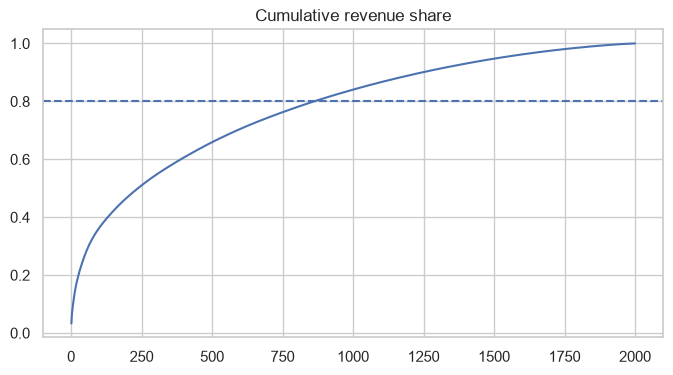

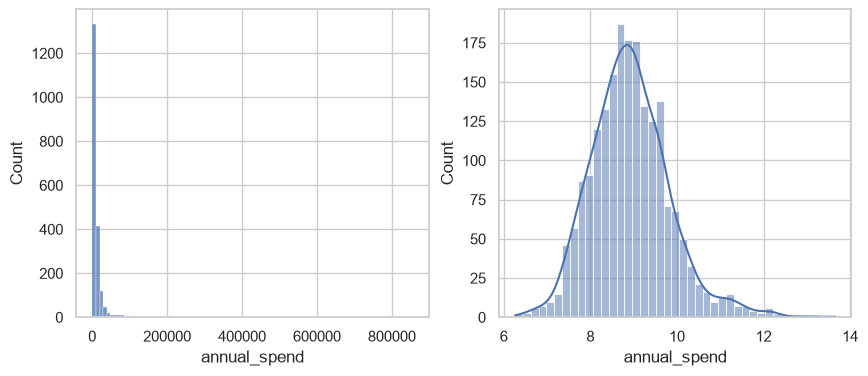

In [34]:
ranked=df.annual_spend.sort_values(ascending=False).reset_index(drop=True)
cum=ranked.cumsum()/ranked.sum()
print('Top 20% revenue share:',ranked.head(int(np.ceil(.2*len(ranked)))).sum()/ranked.sum())
print('Customers to reach 50% revenue:',(cum<=.5).sum()/len(df))
print('Customers to reach 80% revenue:',(cum<=.8).sum()/len(df))
plt.figure(figsize=(8,4)); plt.plot(np.arange(1,len(ranked)+1),cum); plt.axhline(.8,ls='--'); plt.title('Cumulative revenue share'); plt.show()
fig,ax=plt.subplots(1,2,figsize=(10,4)); sns.histplot(df.annual_spend,ax=ax[0]); sns.histplot(np.log1p(df.annual_spend),kde=True,ax=ax[1]); plt.show()

## Task 8: PDF and CDF
PDF/KDE shows where values are dense. CDF gives the share of observations at or below a threshold. Because this is customer-level average delivery time, these probabilities describe customers in this extract, not each individual delivery event.

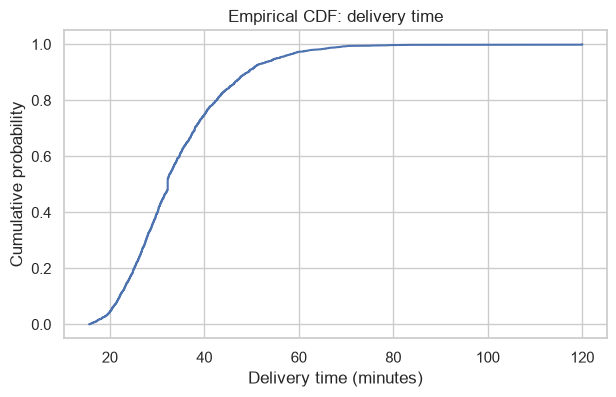

P(delivery <= 30): 0.3985
P(delivery > 45): 0.158
Median: 32.25 P95: 55.4


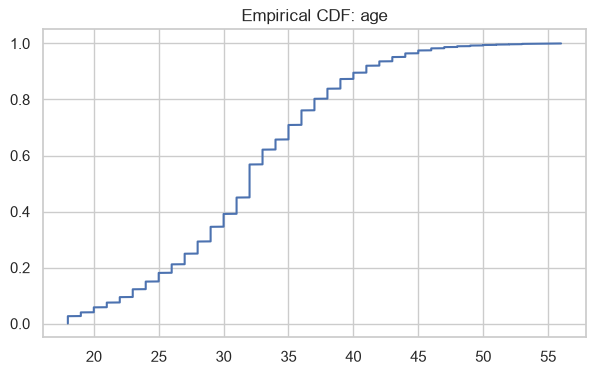

In [36]:
s=np.sort(df.delivery_time_min); cdf=np.arange(1,len(s)+1)/len(s)
plt.figure(figsize=(7,4)); plt.plot(s,cdf); plt.xlabel('Delivery time (minutes)'); plt.ylabel('Cumulative probability'); plt.title('Empirical CDF: delivery time'); plt.show()
print('P(delivery <= 30):',(df.delivery_time_min<=30).mean())
print('P(delivery > 45):',(df.delivery_time_min>45).mean())
print('Median:',df.delivery_time_min.median(),'P95:',df.delivery_time_min.quantile(.95))
s=np.sort(df.age); plt.figure(figsize=(7,4)); plt.plot(s,np.arange(1,len(s)+1)/len(s)); plt.title('Empirical CDF: age'); plt.show()